# Chapitre 7 - Cours 4 : fusion de modèles et tactiques de finetuning

Ce dernier notebook de cours couvre la fin du chapitre 7 : la sous-section *Model Merging
and Multi-Task Finetuning* (*Summing*, *Layer stacking*, *Concatenation*) et la section
*Finetuning Tactics* (*Finetuning frameworks and base models*, *Finetuning
hyperparameters*). La fusion est encore expérimentale ; on implémente donc les méthodes à
la main (`c7.linear_merge`, `c7.task_arithmetic`, `c7.slerp`, `c7.ties_merge`, `c7.dare`),
d'abord sur des vecteurs, puis sur de petits réseaux, pour en voir le fonctionnement. Les
tactiques sont illustrées par de vrais finetunings LoRA courts sur la tâche des tickets.

1. pourquoi fusionner (multi-tâche, oubli catastrophique, fusion contre ensemble) ;
2. fusion par somme : moyenne et arithmétique des tâches ;
3. SLERP ;
4. élaguer les paramètres redondants : TIES et DARE ;
5. empilement de couches et concaténation ;
6. choisir un modèle de base, une méthode et un framework ;
7. le taux d'apprentissage ;
8. taille de lot, accumulation de gradient et nombre d'époques ;
9. le poids de la perte du prompt.

In [1]:
import gc
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch07_finetuning as c7

warnings.filterwarnings("ignore")
c7.setup_style()
llm.seed_everything(0)
DOMS = ["bruité", "occulté", "décalé"]
DCOL = {"original": SLATE, "bruité": INDIGO, "occulté": AMBER, "décalé": TEAL}

## 1. Pourquoi fusionner des modèles (section *Model Merging and Multi-Task Finetuning*)

Le finetuning modifie **un** modèle ; la **fusion** (*model merging*) en combine
**plusieurs**, souvent des finetunings d'une même base, pour obtenir un modèle qui vaut
mieux que ses constituants pris séparément. Les bénéfices cités par le livre :

- **qualité** : deux modèles bons sur des parties différentes d'une tâche peuvent donner
  un modèle meilleur que chacun ;
- **mémoire et coût** : un seul modèle pour plusieurs tâches, idéal pour le déploiement
  **sur appareil** (téléphones, voitures, robots) où la mémoire manque ;
- **multi-tâche** sans les écueils des deux approches classiques : le finetuning
  **simultané** (toutes les tâches mélangées, qui demande plus de données) et le
  finetuning **séquentiel**, sujet à l'**oubli catastrophique** (Kirkpatrick et al.) ;
- **apprentissage fédéré** : fusionner des copies d'un modèle entraînées sur des appareils
  différents ;
- **sans GPU** : une fusion sans finetuning ultérieur se calcule sur CPU.

La fusion se distingue de l'**ensemble** : un ensemble combine les **sorties** de
plusieurs modèles intacts (vote, moyenne), au prix de plusieurs inférences par requête ;
la fusion combine les **paramètres**, et l'on n'a plus qu'un modèle à servir.

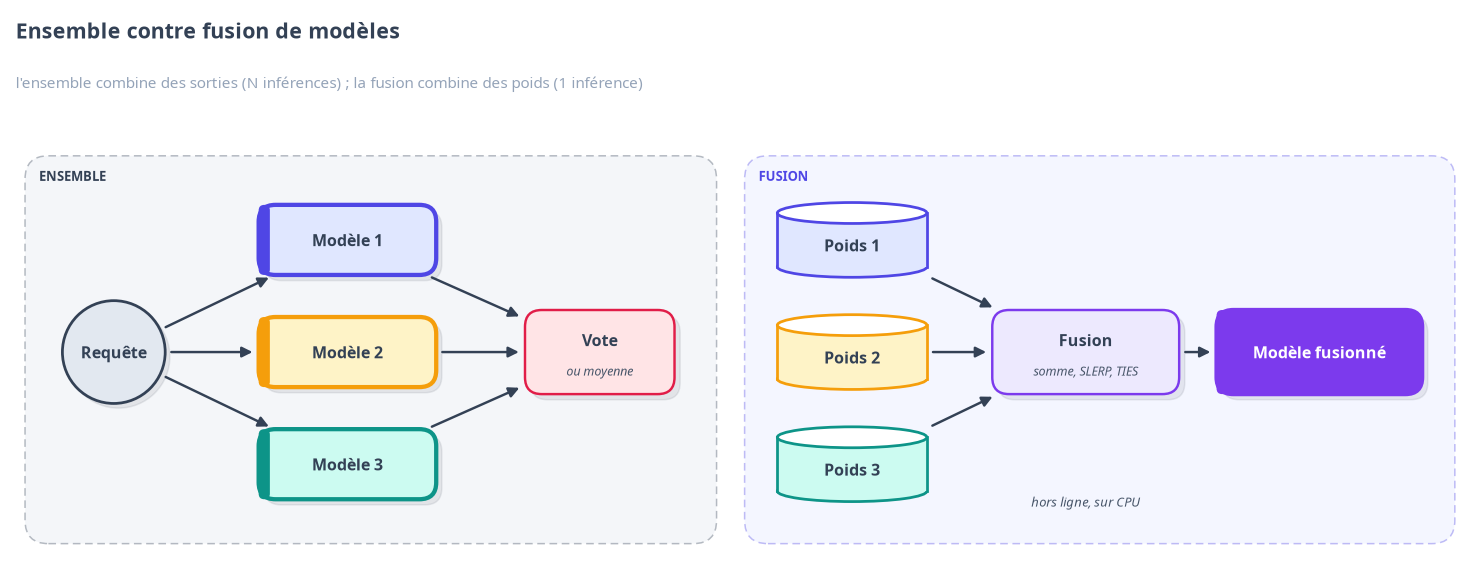

In [2]:
d = Diagram(15.6, 5.0, title="Ensemble contre fusion de modèles",
            subtitle="l'ensemble combine des sorties (N inférences) ; la fusion combine des poids (1 inférence)")
d.group(0.15, 0.25, 7.55, 4.4, "ensemble", SLATE)
d.box("q1", 1.1, 2.3, "Requête", color=SLATE, kind="user", w=1.1)
for i, (nm, col) in enumerate([("m1", INDIGO), ("m2", AMBER), ("m3", TEAL)]):
    d.box(nm, 3.6, 3.5 - i * 1.2, f"Modèle {i + 1}", color=col, kind="model", w=1.9, h=0.75)
    d.arrow("q1", nm)
d.box("vote", 6.3, 2.3, "Vote", sub="ou moyenne", color=ROSE, w=1.6)
for nm in ["m1", "m2", "m3"]:
    d.arrow(nm, "vote")
d.group(7.85, 0.25, 15.45, 4.4, "fusion", INDIGO)
for i, (nm, col) in enumerate([("w1", INDIGO), ("w2", AMBER), ("w3", TEAL)]):
    d.box(nm, 9.0, 3.5 - i * 1.2, f"Poids {i + 1}", color=col, kind="db", w=1.6, h=0.8)
d.box("mg", 11.5, 2.3, "Fusion", sub="somme, SLERP, TIES", color=VIOLET, w=2.0)
for nm in ["w1", "w2", "w3"]:
    d.arrow(nm, "mg")
d.box("mm", 14.0, 2.3, "Modèle fusionné", color=VIOLET, kind="model", w=2.2, filled=True)
d.arrow("mg", "mm")
d.note(11.5, 0.7, "hors ligne, sur CPU", fontsize=8.5)
d.show()

**Notre terrain d'expérience.** Pour expérimenter vite et sur CPU, on reproduit le
scénario « modèle de fondation + finetunings » à petite échelle avec le jeu `digits` de
scikit-learn (images 8 x 8 de chiffres manuscrits). `c7.digits_merge_setup` :

1. **pré-entraîne** un MLP (64 -> 256 -> 256 -> 10, 85 000 paramètres) sur les images
   originales et un peu d'images perturbées ;
2. le **finetune** séparément sur trois « tâches » : images **bruitées**, **occultées**
   (un carré 4 x 4 masqué) et **décalées** d'un pixel.

Commençons par l'oubli catastrophique : finetunons la base **séquentiellement** sur les
trois tâches et suivons l'exactitude sur chacune.

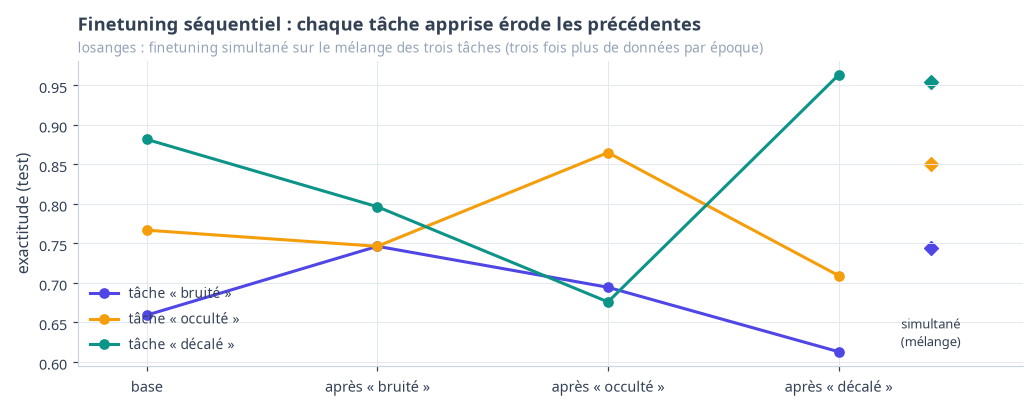

In [3]:
S = c7.digits_merge_setup()
T = S.tasks
seq_hist = [("base", S.evaluate(S.base))]
net = c7.make_mlp(0, S.hidden); c7.set_flat(net, S.base)
for k in DOMS:
    c7.fit_mlp(net, T[k][0], T[k][1], epochs=10, lr=5e-4)
    seq_hist.append((f"après « {k} »", S.evaluate(c7.get_flat(net))))
Xmix = np.concatenate([T[k][0] for k in DOMS]); ymix = np.concatenate([T[k][1] for k in DOMS])
net_mix = c7.make_mlp(0, S.hidden); c7.set_flat(net_mix, S.base); c7.fit_mlp(net_mix, Xmix, ymix, epochs=10, lr=5e-4)
acc_mix = S.evaluate(c7.get_flat(net_mix))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
stages = [s for s, _ in seq_hist]
for k in DOMS:
    ax.plot(stages, [h[k] for _, h in seq_hist], "o-", color=DCOL[k], label=f"tâche « {k} »")
    ax.scatter([len(stages) - 0.6], [acc_mix[k]], marker="D", color=DCOL[k], s=40)
ax.text(len(stages) - 0.6, 0.62, "simultané\n(mélange)", ha="center", fontsize=8.5, color=SLATE)
ax.set_xlim(-0.3, len(stages) - 0.2); ax.set_ylabel("exactitude (test)"); ax.legend(fontsize=9, loc="lower left")
c7.title_sub(ax, "Finetuning séquentiel : chaque tâche apprise érode les précédentes",
             "losanges : finetuning simultané sur le mélange des trois tâches (trois fois plus de données par époque)")
plt.tight_layout(); plt.show()

Chaque finetuning fait progresser sa tâche puis, à l'étape suivante, une partie de ce
gain s'évapore : c'est l'oubli catastrophique, net même entre des tâches aussi proches. Le finetuning simultané évite l'oubli mais demande toutes les données en même
temps. La fusion propose une troisième voie : finetuner en **parallèle**, puis combiner.

> **À retenir.** La fusion combine des **paramètres** (un modèle à servir), l'ensemble
> des **sorties** (N inférences). Elle permet le multi-tâche sans oubli séquentiel ni
> réentraînement commun.

## 2. Fusion par somme : moyenne et arithmétique des tâches (section *Summing*)

**Combinaison linéaire.** Pour deux modèles $A$ et $B$ de même architecture :
$$\text{Merge}(A, B) = \frac{w_A A + w_B B}{w_A + w_B}.$$
D'une simplicité désarmante, elle marche étonnamment bien (Perrone, 1993 ; les *model
soups* de Wortsman et al., 2022, qui moyennent plusieurs finetunings et gagnent en
exactitude sans coût d'inférence). Elle est la plus efficace pour des modèles finetunés
**depuis la même base**. On raisonne alors en **vecteurs de tâche** (*task vectors*, ou
paramètres delta) :
$$\tau_t = \theta_t - \theta_{\text{base}}, \qquad \theta_{\text{fusion}} = \theta_{\text{base}} + \sum_t \lambda_t\, \tau_t.$$
C'est l'**arithmétique des tâches** (Ilharco et al., 2022) : additionner des vecteurs pour
cumuler des capacités, ou en **soustraire** un pour retirer un comportement (biais,
capacité indésirable). La moyenne simple de $n$ finetunings correspond à $\lambda_t = 1/n$.
Visualisons cette géométrie en deux dimensions.

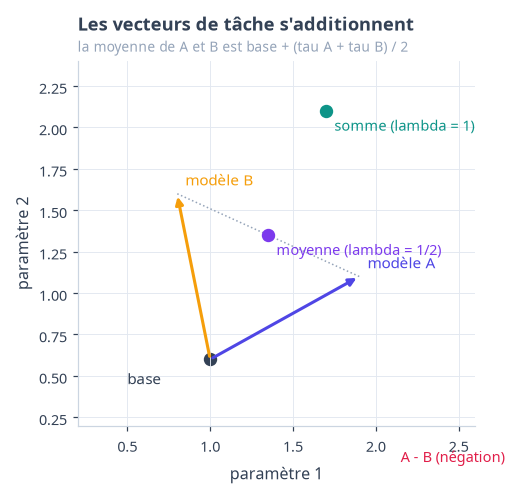

In [4]:
base2 = np.array([1.0, 0.6]); tA = np.array([0.9, 0.5]); tB = np.array([-0.2, 1.0])
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for v, col, lab in [(tA, INDIGO, "tau A"), (tB, AMBER, "tau B")]:
    ax.annotate("", base2 + v, base2, arrowprops=dict(arrowstyle="-|>", color=col, lw=2))
    ax.text(*(base2 + v + 0.05), f"modèle {lab[-1]}", color=col, fontsize=10)
pts = {"moyenne (lambda = 1/2)": base2 + 0.5 * (tA + tB), "somme (lambda = 1)": base2 + tA + tB,
       "A - B (négation)": base2 + tA - tB}
for (lab, p), col in zip(pts.items(), [VIOLET, TEAL, ROSE]):
    ax.scatter(*p, color=col, s=60, zorder=3); ax.text(p[0] + 0.05, p[1] - 0.12, lab, color=col, fontsize=9.5)
ax.scatter(*base2, color=SLATE, s=60); ax.text(base2[0] - 0.5, base2[1] - 0.15, "base", color=SLATE)
ax.plot(*np.array([base2 + tA, base2 + tB]).T, color=GRAY, ls=":", lw=1)
ax.set_xlim(0.2, 2.6); ax.set_ylim(0.2, 2.4); ax.set_aspect("equal")
ax.set_xlabel("paramètre 1"); ax.set_ylabel("paramètre 2")
c7.title_sub(ax, "Les vecteurs de tâche s'additionnent", "la moyenne de A et B est base + (tau A + tau B) / 2")
plt.tight_layout(); plt.show()

**Sur nos réseaux.** On fusionne les trois finetunings par arithmétique des tâches, avec
un coefficient commun $\lambda$ ($\lambda = 1/3$ : moyenne simple), et l'on mesure
l'exactitude sur chaque tâche. Repères : la base, et chaque spécialiste sur sa propre tâche.

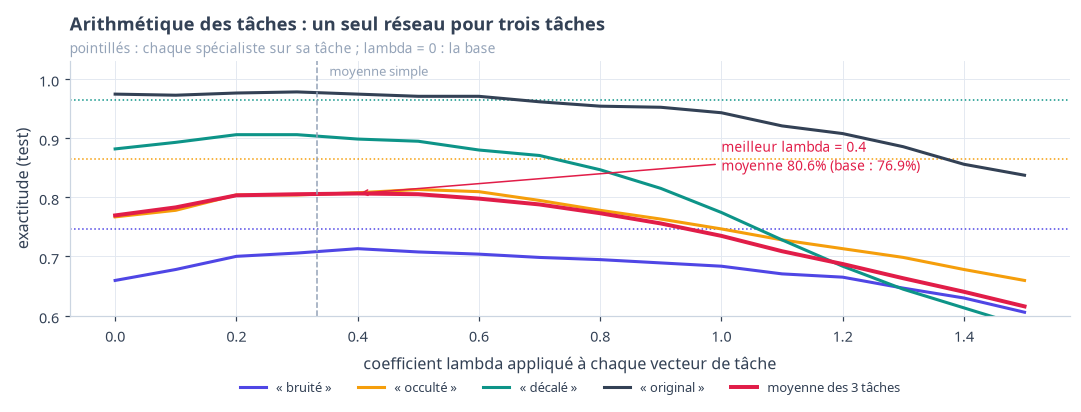

In [5]:
tv = S.task_vectors
lams = np.linspace(0, 1.5, 16)
ta = [S.evaluate(c7.task_arithmetic(S.base, list(tv.values()), l)) for l in lams]
acc_base = S.evaluate(S.base)
acc_spec = {k: S.evaluate(S.finetuned[k])[k] for k in DOMS}
fig, ax = plt.subplots(figsize=(10, 4))
for k in DOMS + ["original"]:
    ax.plot(lams, [a[k] for a in ta], color=DCOL[k], label=f"« {k} »")
    if k in DOMS:
        ax.axhline(acc_spec[k], color=DCOL[k], ls=":", lw=1)
avg = [np.mean([a[k] for k in DOMS]) for a in ta]
best = int(np.argmax(avg))
ax.plot(lams, avg, color=ROSE, lw=2.6, label="moyenne des 3 tâches")
ax.axvline(1 / 3, color=GRAY, ls="--", lw=1); ax.text(1 / 3 + 0.02, 1.005, "moyenne simple", color=GRAY, fontsize=8.5)
ax.annotate(f"meilleur lambda = {lams[best]:.1f}\nmoyenne {avg[best]:.1%} (base : {np.mean([acc_base[k] for k in DOMS]):.1%})",
            (lams[best], avg[best]), xytext=(1.0, 0.845), arrowprops=dict(arrowstyle="->", color=ROSE),
            fontsize=9, color=ROSE)
ax.set_xlabel("coefficient lambda appliqué à chaque vecteur de tâche"); ax.set_ylabel("exactitude (test)")
ax.set_ylim(0.6, 1.03); ax.legend(ncol=5, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
c7.title_sub(ax, "Arithmétique des tâches : un seul réseau pour trois tâches",
             "pointillés : chaque spécialiste sur sa tâche ; lambda = 0 : la base")
plt.tight_layout(); plt.show()

Autour de $\lambda \approx 0{,}3$ à $0{,}5$, le réseau fusionné fait mieux que la base sur
les **trois** tâches à la fois, sans perdre sur les images originales, mais reste en deçà
de chaque spécialiste sur sa propre tâche : c'est le prix de l'**interférence** entre
vecteurs de tâche. Trop grand, $\lambda$ éloigne le modèle de la zone où les finetunings
ont été appris et tout se dégrade.

**Négation de tâche.** Soustraire un vecteur doit retirer la capacité correspondante.
Retirons $\tau_{\text{décalé}}$ :

In [6]:
neg = pd.DataFrame({f"lambda = {l}": S.evaluate(c7.task_arithmetic(S.base, [tv["décalé"]], l))
                    for l in [1.0, 0.0, -1.0, -2.0]}).T
neg.round(3)

,original,bruité,occulté,décalé
lambda = 1.0,0.952,0.609,0.691,0.965
lambda = 0.0,0.974,0.659,0.767,0.881
lambda = -1.0,0.919,0.569,0.654,0.667
lambda = -2.0,0.772,0.419,0.467,0.393


Avec $\lambda < 0$, l'exactitude sur les images décalées chute nettement, alors que les
autres tâches baissent nettement moins : on a « désappris » une capacité de façon ciblée,
sans aucun réentraînement. C'est l'usage proposé pour retirer des comportements
indésirables acquis au pré-entraînement.

> **À retenir.** Fusionner des finetunings d'une même base revient à combiner leurs
> vecteurs de tâche : $\theta = \theta_{base} + \sum \lambda_t \tau_t$. L'addition cumule des
> capacités (avec interférence), la soustraction en retire.

## 3. SLERP (section *Spherical linear interpolation*)

Le livre présente l'**interpolation linéaire sphérique** sans formule ; la voici. Pour deux
vecteurs d'angle $\Omega$ entre leurs directions, et un facteur $t \in [0, 1]$ :
$$\text{slerp}(v_0, v_1; t) = \frac{\sin\big((1-t)\Omega\big)}{\sin \Omega}\, v_0 + \frac{\sin(t\Omega)}{\sin \Omega}\, v_1,
  \qquad \cos \Omega = \frac{v_0 \cdot v_1}{\|v_0\|\,\|v_1\|}.$$
Pour des vecteurs unitaires, le résultat reste sur la sphère : on suit le **grand cercle**
(le plus court chemin à la surface, comme une route aérienne entre deux villes). La
moyenne linéaire, elle, coupe à travers la sphère et **raccourcit** le vecteur : pour deux
vecteurs unitaires orthogonaux, le milieu linéaire a une norme $1/\sqrt 2 \approx 0{,}71$.
Notre `c7.slerp` interpole la direction sur le grand cercle et la norme linéairement.
Comme l'opération ne prend que deux vecteurs, on fusionne plus de deux modèles en
cascade.

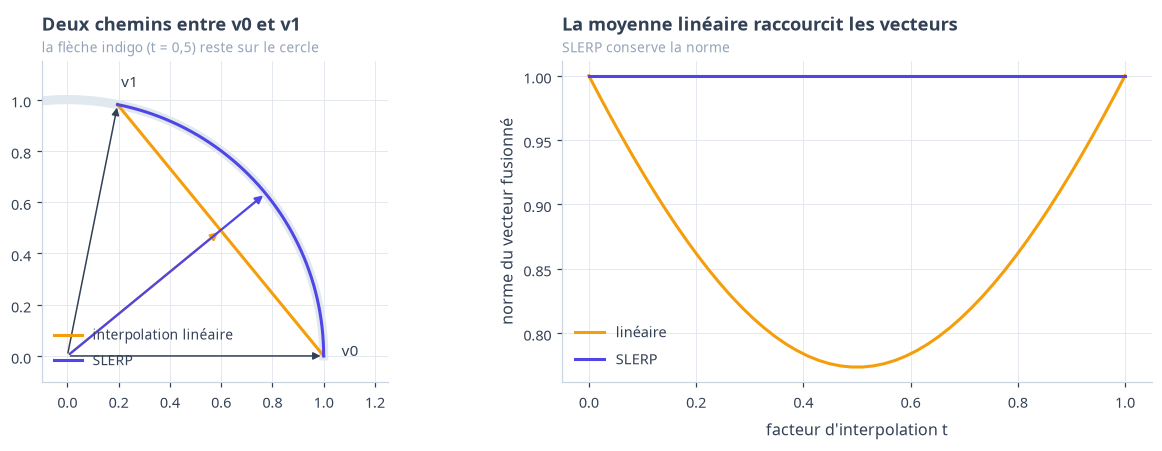

In [7]:
v0, v1 = np.array([1.0, 0.0]), np.array([0.2, 1.0]) / np.linalg.norm([0.2, 1.0])
ts = np.linspace(0, 1, 50)
lin = np.array([(1 - t) * v0 + t * v1 for t in ts]); sl = np.array([c7.slerp(v0, v1, t) for t in ts])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
th = np.linspace(0, np.pi / 2 + 0.3, 200)
axes[0].plot(np.cos(th), np.sin(th), color=LIGHT[SLATE], lw=6)
axes[0].plot(*lin.T, color=AMBER, label="interpolation linéaire")
axes[0].plot(*sl.T, color=INDIGO, label="SLERP")
for v, lab in [(v0, "v0"), (v1, "v1")]:
    axes[0].annotate("", v, (0, 0), arrowprops=dict(arrowstyle="-|>", color=SLATE)); axes[0].text(*(v * 1.07), lab)
m_l, m_s = 0.5 * (v0 + v1), c7.slerp(v0, v1, 0.5)
for m_, col in [(m_l, AMBER), (m_s, INDIGO)]:
    axes[0].annotate("", m_, (0, 0), arrowprops=dict(arrowstyle="-|>", color=col, lw=1.5))
axes[0].set_aspect("equal"); axes[0].set_xlim(-0.1, 1.25); axes[0].set_ylim(-0.1, 1.15); axes[0].legend(fontsize=9, loc="lower left")
c7.title_sub(axes[0], "Deux chemins entre v0 et v1", "la flèche indigo (t = 0,5) reste sur le cercle")
axes[1].plot(ts, np.linalg.norm(lin, axis=1), color=AMBER, label="linéaire")
axes[1].plot(ts, np.linalg.norm(sl, axis=1), color=INDIGO, label="SLERP")
axes[1].set_xlabel("facteur d'interpolation t"); axes[1].set_ylabel("norme du vecteur fusionné"); axes[1].legend()
c7.title_sub(axes[1], "La moyenne linéaire raccourcit les vecteurs", "SLERP conserve la norme")
plt.tight_layout(); plt.show()

**Sur nos réseaux.** On interpole entre les spécialistes « bruité » et « occulté » (dans
l'espace des vecteurs de tâche), linéairement et par SLERP.

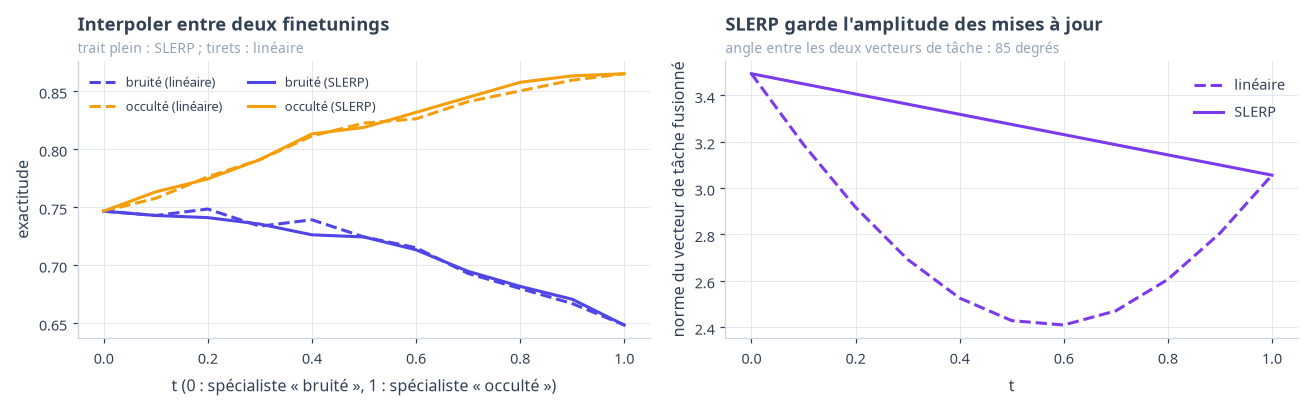

In [8]:
tts = np.linspace(0, 1, 11)
rows = []
for t in tts:
    for meth, f in [("linéaire", lambda a, b, t: (1 - t) * a + t * b), ("SLERP", c7.slerp)]:
        tau = f(tv["bruité"], tv["occulté"], t)
        acc = S.evaluate(S.base + tau)
        rows.append({"t": t, "méthode": meth, **acc, "norme de tau": np.linalg.norm(tau)})
sl_df = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for meth, ls in [("linéaire", "--"), ("SLERP", "-")]:
    sub = sl_df[sl_df["méthode"] == meth]
    for k in ["bruité", "occulté"]:
        axes[0].plot(sub["t"], sub[k], ls, color=DCOL[k], label=f"{k} ({meth})")
    axes[1].plot(sub["t"], sub["norme de tau"], ls, color=VIOLET, label=meth)
axes[0].set_xlabel("t (0 : spécialiste « bruité », 1 : spécialiste « occulté »)"); axes[0].set_ylabel("exactitude")
axes[0].legend(fontsize=8.5, ncol=2)
c7.title_sub(axes[0], "Interpoler entre deux finetunings", "trait plein : SLERP ; tirets : linéaire")
axes[1].set_xlabel("t"); axes[1].set_ylabel("norme du vecteur de tâche fusionné"); axes[1].legend()
c7.title_sub(axes[1], "SLERP garde l'amplitude des mises à jour", f"angle entre les deux vecteurs de tâche : "
             f"{np.degrees(np.arccos(tv['bruité'] @ tv['occulté'] / np.linalg.norm(tv['bruité']) / np.linalg.norm(tv['occulté']))):.0f} degrés")
plt.tight_layout(); plt.show()

Les vecteurs de tâche sont presque orthogonaux (c'est typique : en grande dimension, deux
finetunings indépendants vont dans des directions quasi perpendiculaires). La moyenne
linéaire réduit alors la norme de la mise à jour d'environ 30 % au milieu, ce qui
l'affaiblit ; SLERP la conserve. Sur ce petit exemple, les deux méthodes donnent des
exactitudes voisines : l'intérêt de SLERP se discute au cas par cas, ce qui explique que
les outils de fusion proposent les deux.

> **À retenir.** SLERP interpole sur le grand cercle et conserve la norme ; il ne fusionne
> que deux vecteurs à la fois. En grande dimension, les vecteurs de tâche sont presque
> orthogonaux, et la moyenne linéaire les raccourcit.